# ARIEL: Body Decoders

In [1]:
from ariel.rendering import (  # chooses the OpenGL backend before MuJoCo loads
    single_frame_renderer,
)

One-off setup: testing which OpenGL backends work on this machine. The result is saved to mujoco_user_config.json; 
this will not be repeated.

Output()

In [2]:
# Third-party libraries
from typing import cast

import mujoco as mj
import numpy as np
from rich.console import Console

# Global constants
SEED = 42

# Global functions
console = Console()
RNG = np.random.default_rng(SEED)

## ARIEL Modules

In [3]:
# Local libraries
from ariel.body_phenotypes.robogen_lite.config import (
    NUM_OF_FACES,
    NUM_OF_ROTATIONS,
    NUM_OF_TYPES_OF_MODULES,
)
from ariel.body_phenotypes.robogen_lite.constructor import (
    construct_mjspec_from_graph,
)
from ariel.simulation.environments import SimpleFlatWorld

# System parameters
num_modules = 30
console.log(f"Number of modules: {num_modules}")

[16:22:42] Number of modules: 30                                                                    ]8;id=781562;file:///tmp/ipykernel_454899/359265747.py\359265747.py]8;;\:]8;id=512123;file:///tmp/ipykernel_454899/359265747.py#14\14]8;;\

### Highest Probability Decoder

In [4]:
from ariel.body_phenotypes.robogen_lite.decoders import (
    HighProbabilityDecoder,
    draw_graph,
)

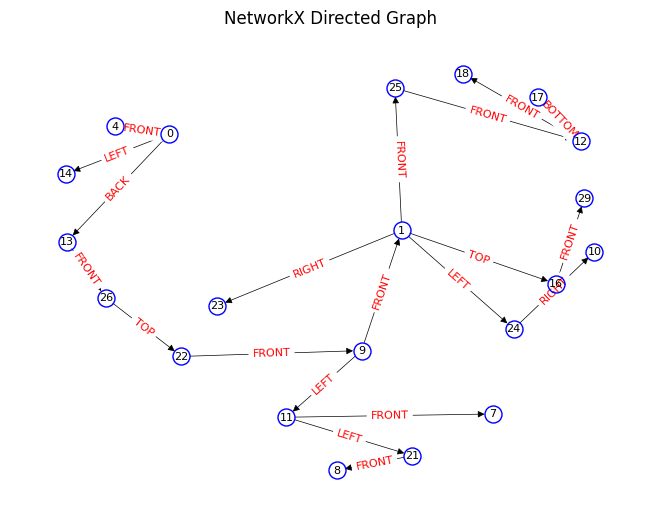

In [5]:
# "Type" probability space
type_probability_space = RNG.random(
    size=(num_modules, NUM_OF_TYPES_OF_MODULES),
    dtype=np.float32,
)

# "Connection" probability space
conn_probability_space = RNG.random(
    size=(num_modules, num_modules, NUM_OF_FACES),
    dtype=np.float32,
)

# "Rotation" probability space
rotation_probability_space = RNG.random(
    size=(num_modules, NUM_OF_ROTATIONS),
    dtype=np.float32,
)

# Decode the high-probability graph
hpd = HighProbabilityDecoder(num_modules)
graph = hpd.probability_matrices_to_graph(
    type_probability_space,
    conn_probability_space,
    rotation_probability_space,
)

# Visualize the graph
draw_graph(graph)

           DoF (model.nv): 17, Actuators (model.nu): 11                                             ]8;id=88741;file:///tmp/ipykernel_454899/575877808.py\575877808.py]8;;\:]8;id=588943;file:///tmp/ipykernel_454899/575877808.py#19\19]8;;\

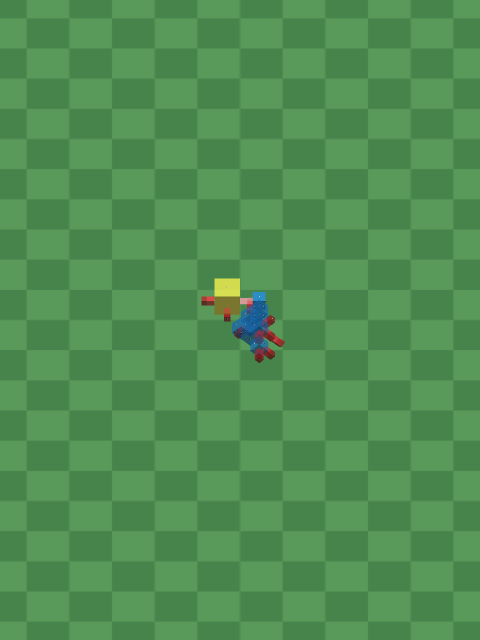

In [6]:
# Build the robot from the graph
core = construct_mjspec_from_graph(graph)

# MuJoCo basics
world = SimpleFlatWorld()

# Set random colors for geoms
for i in range(len(core.spec.geoms)):
    core.spec.geoms[i].rgba[-1] = 0.5

# Spawn the robot at the world
world.spawn(core.spec)

# Compile the model
model = cast("mj.MjModel", world.spec.compile())
data = mj.MjData(model)

# Number of actuators and DoFs
console.log(f"DoF (model.nv): {model.nv}, Actuators (model.nu): {model.nu}")

# Reset state and time of simulation
mj.mj_resetData(model, data)

# Render
single_frame_renderer(model, data, steps=10)